
# RQ22 — How much performance is explained by evidence quantity and evidence structure?

## Scientific question

**How much of supervised predictive performance can be related to the amount and structure of available evidence, and how much of the redundancy effect (`R`) remains after accounting for measurable information quantity and sequence-space structure?**

RQ22 consolidates evidence-state information that was previously distributed across RQ2, RQ3, RQ5, and the Low-N analysis. It does **not** train models, regenerate predictions, recalculate common-test predictions, or bootstrap uncertainty.

The roadmap variables are explicitly represented:

- `n_train`
- `n_test`
- positive support when biologically defined
- prevalence for binary tasks
- cluster richness
- cluster density / entities per cluster
- `R`
- `S`
- predictive performance (`MCC`)

All model-level analyses remain blocked by:

```text
task × representation × algorithm
```

so the notebook does not mistake easier tasks or stronger model families for an evidence-quantity effect.



## Interpretation contract

### Evidence quantity and evidence structure are not interchangeable

- `R` changes the available sequence universe and therefore modifies both **quantity** and **redundancy structure**.
- `S` primarily changes the **homology-group topology of the split** at fixed R.
- S-level cluster counts are used as **relative richness / granularity statistics**. They are not interpreted as literal survival of identical clusters across independently reconstructed R universes.

### Positive support

For binary supervised tasks, RQ22 records:

- `n_positive_train`
- `n_positive_test`
- `train_prevalence`
- `test_prevalence`

For multiclass, there is no single biologically meaningful “positive” class. RQ22 therefore records:

- number of observed classes;
- minimum class support in train/test;
- maximum class support in train/test.

The multiclass minimum-class support is an evidence-balance diagnostic, **not a substitute for binary positive support**.

### Statistical scope

RQ22 is descriptive.

It uses three complementary levels:

1. **unique dataset cells** (`task × R × S`; 112 cells) to avoid pseudoreplicating the same evidence state across 20 model strategies;
2. **blocked model surfaces** (`task × representation × algorithm`; 140 surfaces) to quantify how evidence-performance associations vary by model family;
3. **extreme R/S contrasts** to connect changes in MCC with changes in evidence quantity/structure.

No p-values are used to claim causality.

### R and S treatment

`R` and `S` are categorical ordered protocol factors in the primary nested models. Numeric trend versions are used only as descriptive diagnostics.

### Collinearity guardrail

Several evidence quantities are algebraically or biologically dependent.

For example:

\[
\text{train entities per cluster}
=
\frac{n_{\mathrm{train}}}{n_{\mathrm{clusters,train}}}.
\]

Therefore density is analyzed descriptively but is **not simultaneously entered with its two defining components** in the main nested model.

Likewise, positive support, prevalence, and train size are not forced into the same all-task model.


In [1]:

from pathlib import Path
import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 400)
pd.set_option("display.width", 260)
pd.set_option("display.max_rows", 400)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]
PRIMARY_METRIC = "mcc"

TASK_PATHS = {
    "global_easy": "global_easy",
    "global_hard": "global_hard",
    "global_mixed": "global_mixed",
    "subtype_endolysin": "subtype_binary/endolysin",
    "subtype_depolymerase": "subtype_binary/depolymerase",
    "subtype_val": "subtype_binary/virion_associated_lytic_enzyme",
    "multiclass_clean": "multiclass_clean",
}

BINARY_TASKS = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

MULTICLASS_TASKS = ["multiclass_clean"]

REP_ORDER = [
    "roxy_48",
    "onehot_1024",
    "esm2_t6_8m",
    "esm2_t30_150m",
]
ALG_ORDER = ["KNN", "LR", "MLP", "RF", "XGB"]


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        master = candidate / "results/analysis_supervised/stage12a/supervised_master_results.tsv"
        pred = candidate / "data/predictive_universe"
        if master.is_file() and pred.is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate PhageLysClass project root containing "
        "Stage12A supervised_master_results.tsv and data/predictive_universe."
    )


ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
PREDICTIVE_ROOT = ROOT / "data/predictive_universe"
CACHE_ROOT = ROOT / "results/analysis_supervised/notebook_cache"
RQ22_OUT = CACHE_ROOT / "rq22_evidence_quantity_structure"
FIG_DIR = RQ22_OUT / "figures"

RQ22_OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("RQ22_OUT:", RQ22_OUT)
print("No model training, prediction regeneration, common-test recalculation, or bootstrap is performed.")


ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
RQ22_OUT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq22_evidence_quantity_structure
No model training, prediction regeneration, common-test recalculation, or bootstrap is performed.


## 1. Load and validate the frozen supervised benchmark

In [2]:

master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

required_master = {
    "task", "R", "S", "representation", "algorithm", PRIMARY_METRIC
}
missing = required_master - set(master.columns)
if missing:
    raise KeyError(f"Supervised master missing required columns: {sorted(missing)}")

for c in ["R", "S", PRIMARY_METRIC]:
    master[c] = pd.to_numeric(master[c], errors="raise")

master["R"] = master["R"].astype(int)
master["S"] = master["S"].astype(int)

assert len(master) == 2240, f"Expected 2240 supervised rows, found {len(master)}"
assert set(master["task"].unique()) == set(TASK_PATHS)
assert set(master["R"].unique()) == set(R_LEVELS)
assert set(master["S"].unique()) == set(S_LEVELS)

surface_coverage = (
    master.groupby(["task", "representation", "algorithm"])
    .size()
)
assert len(surface_coverage) == 140
assert surface_coverage.eq(16).all()

cell_strategy_coverage = (
    master.groupby(["task", "R", "S"])
    .size()
)
assert len(cell_strategy_coverage) == 112
assert cell_strategy_coverage.eq(20).all()

print("Supervised rows:", len(master))
print("Unique task×R×S cells:", len(cell_strategy_coverage))
print("Complete model surfaces:", len(surface_coverage))
print("SUPERVISED_PREFLIGHT_OK")


Supervised rows: 2240
Unique task×R×S cells: 112
Complete model surfaces: 140
SUPERVISED_PREFLIGHT_OK



## 2. Reconstruct the evidence state from frozen predictive-universe files

The evidence table is reconstructed directly from:

```text
data/predictive_universe/<task>/<R>_<S>/eligible_entities.tsv.gz
```

This avoids assuming that a previous notebook cache contains every variable required by RQ22.

Expected closure for every supervised cell:

- train and test are non-empty;
- exact entity assignment is already frozen upstream;
- train and test do not share S-level clusters;
- all 112 task×R×S cells are present.


In [3]:

def infer_split_column(df):
    for c in ["split", "outer_split", "partition", "set"]:
        if c in df.columns:
            return c
    raise KeyError(f"No split column found. Columns: {list(df.columns)}")


def infer_cluster_column(df):
    for c in ["cluster_id", "mmseqs_cluster_id", "cluster"]:
        if c in df.columns:
            return c
    raise KeyError(f"No cluster column found. Columns: {list(df.columns)}")


def normalize_binary_mask(series):
    s = series.astype(str).str.strip().str.lower()
    numeric = pd.to_numeric(series, errors="coerce")

    if numeric.notna().all() and set(numeric.unique()) <= {0.0, 1.0}:
        return numeric.eq(1.0)

    pos_tokens = {
        "1", "1.0", "positive", "pos", "p", "true", "yes",
        "lytic", "target",
    }
    neg_tokens = {
        "0", "0.0", "negative", "neg", "n", "false", "no",
        "non-lytic", "non_lytic", "background",
    }

    vals = set(s.dropna().unique())
    if vals and vals <= (pos_tokens | neg_tokens) and vals & pos_tokens:
        return s.isin(pos_tokens)

    return None


def infer_binary_label_column(df):
    for c in [
        "y", "y_true", "label", "target",
        "binary_label", "class_label", "class_name",
    ]:
        if c not in df.columns:
            continue
        mask = normalize_binary_mask(df[c])
        if mask is not None:
            return c, mask
    return None, None


def infer_multiclass_column(df):
    candidates = [
        "class_name", "label", "target", "y_true", "y",
        "class_label", "functional_class", "subtype",
    ]
    for c in candidates:
        if c not in df.columns:
            continue
        vals = df[c].dropna().astype(str)
        if vals.nunique() >= 3:
            return c
    return None


def safe_entropy(counts):
    counts = np.asarray(counts, dtype=float)
    counts = counts[counts > 0]
    if len(counts) == 0:
        return np.nan
    p = counts / counts.sum()
    return float(-(p * np.log(p)).sum())


def predictive_path(task, r, s):
    return (
        PREDICTIVE_ROOT
        / TASK_PATHS[task]
        / f"R{r}_S{s}"
        / "eligible_entities.tsv.gz"
    )


evidence_rows = []

for task, task_path in TASK_PATHS.items():
    for r in R_LEVELS:
        for s in S_LEVELS:
            path = predictive_path(task, r, s)
            if not path.is_file():
                raise FileNotFoundError(path)

            df = pd.read_csv(path, sep="\t", low_memory=False)

            split_col = infer_split_column(df)
            cluster_col = infer_cluster_column(df)

            split = df[split_col].astype(str).str.strip().str.lower()
            train = split.eq("train")
            test = split.eq("test")

            if train.sum() == 0 or test.sum() == 0:
                raise ValueError(f"{task} R{r} S{s}: empty train or test split")

            train_clusters = set(df.loc[train, cluster_col].astype(str))
            test_clusters = set(df.loc[test, cluster_col].astype(str))
            shared_clusters = train_clusters & test_clusters

            row = {
                "task": task,
                "R": r,
                "S": s,
                "source_path": str(path),
                "n_total": int(len(df)),
                "n_train": int(train.sum()),
                "n_test": int(test.sum()),
                "test_fraction": float(test.mean()),
                "n_clusters_total": int(df[cluster_col].nunique()),
                "n_clusters_train": int(df.loc[train, cluster_col].nunique()),
                "n_clusters_test": int(df.loc[test, cluster_col].nunique()),
                "shared_train_test_clusters": int(len(shared_clusters)),
            }

            row["train_entities_per_cluster"] = (
                row["n_train"] / row["n_clusters_train"]
                if row["n_clusters_train"] > 0 else np.nan
            )
            row["test_entities_per_cluster"] = (
                row["n_test"] / row["n_clusters_test"]
                if row["n_clusters_test"] > 0 else np.nan
            )
            row["total_entities_per_cluster"] = (
                row["n_total"] / row["n_clusters_total"]
                if row["n_clusters_total"] > 0 else np.nan
            )

            # Binary positive support.
            row.update({
                "label_mode": pd.NA,
                "label_column": pd.NA,
                "n_positive_train": np.nan,
                "n_positive_test": np.nan,
                "train_prevalence": np.nan,
                "test_prevalence": np.nan,
                "n_classes_train": np.nan,
                "n_classes_test": np.nan,
                "min_class_support_train": np.nan,
                "min_class_support_test": np.nan,
                "max_class_support_train": np.nan,
                "max_class_support_test": np.nan,
                "class_entropy_train": np.nan,
                "class_entropy_test": np.nan,
            })

            if task in BINARY_TASKS:
                label_col, positive_mask = infer_binary_label_column(df)
                if label_col is None:
                    raise KeyError(
                        f"{task} R{r} S{s}: could not infer a binary label column. "
                        f"Columns: {list(df.columns)}"
                    )

                npos_train = int((train & positive_mask).sum())
                npos_test = int((test & positive_mask).sum())

                row.update({
                    "label_mode": "binary",
                    "label_column": label_col,
                    "n_positive_train": npos_train,
                    "n_positive_test": npos_test,
                    "train_prevalence": npos_train / int(train.sum()),
                    "test_prevalence": npos_test / int(test.sum()),
                    "n_classes_train": 2,
                    "n_classes_test": 2,
                    "min_class_support_train": min(npos_train, int(train.sum()) - npos_train),
                    "min_class_support_test": min(npos_test, int(test.sum()) - npos_test),
                    "max_class_support_train": max(npos_train, int(train.sum()) - npos_train),
                    "max_class_support_test": max(npos_test, int(test.sum()) - npos_test),
                })

                train_counts = [npos_train, int(train.sum()) - npos_train]
                test_counts = [npos_test, int(test.sum()) - npos_test]
                row["class_entropy_train"] = safe_entropy(train_counts)
                row["class_entropy_test"] = safe_entropy(test_counts)

            else:
                class_col = infer_multiclass_column(df)
                if class_col is None:
                    raise KeyError(
                        f"{task} R{r} S{s}: could not infer multiclass column. "
                        f"Columns: {list(df.columns)}"
                    )

                train_counts = df.loc[train, class_col].astype(str).value_counts()
                test_counts = df.loc[test, class_col].astype(str).value_counts()

                row.update({
                    "label_mode": "multiclass",
                    "label_column": class_col,
                    "n_classes_train": int(train_counts.size),
                    "n_classes_test": int(test_counts.size),
                    "min_class_support_train": int(train_counts.min()),
                    "min_class_support_test": int(test_counts.min()),
                    "max_class_support_train": int(train_counts.max()),
                    "max_class_support_test": int(test_counts.max()),
                    "class_entropy_train": safe_entropy(train_counts.values),
                    "class_entropy_test": safe_entropy(test_counts.values),
                })

            evidence_rows.append(row)

evidence = pd.DataFrame(evidence_rows)

assert len(evidence) == 112
assert not evidence.duplicated(["task", "R", "S"]).any()
assert evidence["shared_train_test_clusters"].eq(0).all()
assert evidence["n_train"].gt(0).all()
assert evidence["n_test"].gt(0).all()
assert evidence.loc[evidence["task"].isin(BINARY_TASKS), "n_positive_train"].notna().all()
assert evidence.loc[evidence["task"].isin(BINARY_TASKS), "n_positive_test"].notna().all()

print("Evidence cells:", len(evidence))
print("Binary cells with positive support:", evidence["n_positive_train"].notna().sum())
print("Multiclass cells:", evidence["label_mode"].eq("multiclass").sum())
print("Shared train/test clusters:", evidence["shared_train_test_clusters"].sum())
print("EVIDENCE_RECONSTRUCTION_OK")
display(evidence.head())


Evidence cells: 112
Binary cells with positive support: 96
Multiclass cells: 16
Shared train/test clusters: 0
EVIDENCE_RECONSTRUCTION_OK


,task,R,S,source_path,n_total,n_train,n_test,test_fraction,n_clusters_total,n_clusters_train,n_clusters_test,shared_train_test_clusters,train_entities_per_cluster,test_entities_per_cluster,total_entities_per_cluster,label_mode,label_column,n_positive_train,n_positive_test,train_prevalence,test_prevalence,n_classes_train,n_classes_test,min_class_support_train,min_class_support_test,max_class_support_train,max_class_support_test,class_entropy_train,class_entropy_test
0,global_easy,90,90,/home/david/Desktop/colabs/inta_project/phagel...,30092,21049,9043,0.300512,30083,21041,9042,0,1.000380,1.000111,1.000299,binary,label,3324.0,1439.0,0.157917,0.159129,2,2,3324,1439,17725,7604,0.436200,0.438222
1,global_easy,90,70,/home/david/Desktop/colabs/inta_project/phagel...,30092,21050,9042,0.300479,21485,15029,6456,0,1.400625,1.400558,1.400605,binary,label,3321.0,1442.0,0.157767,0.159478,2,2,3321,1442,17729,7600,0.435949,0.438803
2,global_easy,90,50,/home/david/Desktop/colabs/inta_project/phagel...,30092,21068,9024,0.299880,14786,10284,4502,0,2.048619,2.004442,2.035168,binary,label,3380.0,1383.0,0.160433,0.153258,2,2,3380,1383,17688,7641,0.440387,0.428319
3,global_easy,90,30,/home/david/Desktop/colabs/inta_project/phagel...,30092,21076,9016,0.299615,8995,6238,2757,0,3.378647,3.270221,3.345414,binary,label,3284.0,1479.0,0.155817,0.164042,2,2,3284,1479,17792,7537,0.432668,0.446312
4,global_easy,70,90,/home/david/Desktop/colabs/inta_project/phagel...,21512,15058,6454,0.300019,21507,15055,6452,0,1.000199,1.000310,1.000232,binary,label,2437.0,1026.0,0.161841,0.158971,2,2,2437,1026,12621,5428,0.442710,0.437960


## 3. Derive retention, richness, density, and S-topology diagnostics

In [4]:

# R-relative state at fixed task × S, using R90 as reference.
derived_rows = []

for (task, s), grp in evidence.groupby(["task", "S"], sort=False):
    base = grp[grp["R"].eq(90)]
    if len(base) != 1:
        raise RuntimeError(f"Missing unique R90 baseline for {task}, S{s}")
    base = base.iloc[0]

    for rec in grp.to_dict("records"):
        row = rec.copy()
        row["entity_retention_to_R90"] = (
            rec["n_train"] / base["n_train"]
            if base["n_train"] > 0 else np.nan
        )
        row["cluster_richness_to_R90"] = (
            rec["n_clusters_train"] / base["n_clusters_train"]
            if base["n_clusters_train"] > 0 else np.nan
        )
        row["density_ratio_to_R90"] = (
            rec["train_entities_per_cluster"] / base["train_entities_per_cluster"]
            if base["train_entities_per_cluster"] > 0 else np.nan
        )

        if pd.notna(rec["n_positive_train"]) and base["n_positive_train"] > 0:
            row["positive_support_retention_to_R90"] = (
                rec["n_positive_train"] / base["n_positive_train"]
            )
        else:
            row["positive_support_retention_to_R90"] = np.nan

        derived_rows.append(row)

evidence = pd.DataFrame(derived_rows)

# S-relative topology at fixed task × R, using S90 as descriptive reference.
sref = evidence[
    evidence["S"].eq(90)
][
    ["task", "R", "n_train", "n_test", "n_clusters_train", "n_clusters_test",
     "train_entities_per_cluster", "test_entities_per_cluster"]
].rename(columns={
    "n_train": "n_train_S90",
    "n_test": "n_test_S90",
    "n_clusters_train": "n_clusters_train_S90",
    "n_clusters_test": "n_clusters_test_S90",
    "train_entities_per_cluster": "train_density_S90",
    "test_entities_per_cluster": "test_density_S90",
})

evidence = evidence.merge(
    sref,
    on=["task", "R"],
    how="left",
    validate="many_to_one",
)

evidence["train_size_ratio_to_S90"] = evidence["n_train"] / evidence["n_train_S90"]
evidence["test_size_ratio_to_S90"] = evidence["n_test"] / evidence["n_test_S90"]
evidence["train_cluster_ratio_to_S90"] = (
    evidence["n_clusters_train"] / evidence["n_clusters_train_S90"]
)
evidence["test_cluster_ratio_to_S90"] = (
    evidence["n_clusters_test"] / evidence["n_clusters_test_S90"]
)
evidence["train_density_ratio_to_S90"] = (
    evidence["train_entities_per_cluster"] / evidence["train_density_S90"]
)
evidence["test_density_ratio_to_S90"] = (
    evidence["test_entities_per_cluster"] / evidence["test_density_S90"]
)

# Log transforms used in descriptive models.
for c in [
    "n_train", "n_test", "n_clusters_train", "n_clusters_test",
    "train_entities_per_cluster", "test_entities_per_cluster",
    "n_positive_train", "n_positive_test",
    "min_class_support_train", "min_class_support_test",
]:
    evidence[f"log1p_{c}"] = np.log1p(pd.to_numeric(evidence[c], errors="coerce"))

display(
    evidence.groupby("R")[
        [
            "entity_retention_to_R90",
            "cluster_richness_to_R90",
            "density_ratio_to_R90",
        ]
    ].median()
)

display(
    evidence.groupby("S")[
        [
            "train_size_ratio_to_S90",
            "test_size_ratio_to_S90",
            "train_cluster_ratio_to_S90",
            "test_cluster_ratio_to_S90",
            "train_density_ratio_to_S90",
        ]
    ].median()
)


,entity_retention_to_R90,cluster_richness_to_R90,density_ratio_to_R90
R,,,
30,0.307481,0.559600,0.623930
50,0.497003,0.856301,0.623784
70,0.717154,1.000193,0.720721
90,1.000000,1.000000,1.000000


,train_size_ratio_to_S90,test_size_ratio_to_S90,train_cluster_ratio_to_S90,test_cluster_ratio_to_S90,train_density_ratio_to_S90
S,,,,,
30,1.000456,0.998934,0.553651,0.560003,1.824082
50,1.000052,0.999880,0.858497,0.856154,1.195356
70,0.999802,1.000461,0.998348,0.997698,1.000731
90,1.000000,1.000000,1.000000,1.000000,1.000000



## 4. Merge performance with evidence state

The full merged table has 2,240 model rows, but the same evidence state is repeated across the 20 model strategies belonging to a given `task × R × S` cell.

Therefore:

- **global evidence models** use the 112 unique dataset cells after summarizing MCC across strategies;
- **model-family heterogeneity** uses blocked 16-cell surfaces;
- the notebook never treats all 2,240 rows as independent evidence observations in a global regression.


In [5]:

merged = master.merge(
    evidence,
    on=["task", "R", "S"],
    how="left",
    validate="many_to_one",
)

assert len(merged) == 2240
assert merged["n_train"].notna().all()
assert merged["n_clusters_train"].notna().all()

cell_performance = (
    master.groupby(["task", "R", "S"], as_index=False)
    .agg(
        median_mcc=(PRIMARY_METRIC, "median"),
        mean_mcc=(PRIMARY_METRIC, "mean"),
        q25_mcc=(PRIMARY_METRIC, lambda x: x.quantile(0.25)),
        q75_mcc=(PRIMARY_METRIC, lambda x: x.quantile(0.75)),
        min_mcc=(PRIMARY_METRIC, "min"),
        max_mcc=(PRIMARY_METRIC, "max"),
    )
)

cell_state = cell_performance.merge(
    evidence,
    on=["task", "R", "S"],
    how="left",
    validate="one_to_one",
)

assert len(cell_state) == 112

print("Merged model rows:", len(merged))
print("Unique evidence-performance cells:", len(cell_state))
display(cell_state.head())


Merged model rows: 2240
Unique evidence-performance cells: 112


,task,R,S,median_mcc,mean_mcc,q25_mcc,q75_mcc,min_mcc,max_mcc,source_path,n_total,n_train,n_test,test_fraction,n_clusters_total,n_clusters_train,n_clusters_test,shared_train_test_clusters,train_entities_per_cluster,test_entities_per_cluster,total_entities_per_cluster,label_mode,label_column,n_positive_train,n_positive_test,train_prevalence,test_prevalence,n_classes_train,n_classes_test,min_class_support_train,min_class_support_test,max_class_support_train,max_class_support_test,class_entropy_train,class_entropy_test,entity_retention_to_R90,cluster_richness_to_R90,density_ratio_to_R90,positive_support_retention_to_R90,n_train_S90,n_test_S90,n_clusters_train_S90,n_clusters_test_S90,train_density_S90,test_density_S90,train_size_ratio_to_S90,test_size_ratio_to_S90,train_cluster_ratio_to_S90,test_cluster_ratio_to_S90,train_density_ratio_to_S90,test_density_ratio_to_S90,log1p_n_train,log1p_n_test,log1p_n_clusters_train,log1p_n_clusters_test,log1p_train_entities_per_cluster,log1p_test_entities_per_cluster,log1p_n_positive_train,log1p_n_positive_test,log1p_min_class_support_train,log1p_min_class_support_test
0,global_easy,30,30,0.664537,0.629681,0.460244,0.809177,0.134918,0.887662,/home/david/Desktop/colabs/inta_project/phagel...,8977,6290,2687,0.299320,8957,6279,2678,0,1.001752,1.003361,1.002233,binary,label,1109.0,495.0,0.176312,0.184220,2,2,1109,495,5181,2192,0.465754,0.477733,0.298444,1.006573,0.296495,0.337698,6275,2702,6275,2700,1.00000,1.000741,1.002390,0.994449,1.000637,0.991852,1.001752,1.002618,8.746875,7.896553,8.745125,7.893199,0.694023,0.694826,7.012115,6.206576,7.012115,6.206576
1,global_easy,30,50,0.644903,0.633714,0.447732,0.791290,0.116259,0.904136,/home/david/Desktop/colabs/inta_project/phagel...,8977,6297,2680,0.298541,8970,6294,2676,0,1.000477,1.001495,1.000780,binary,label,1118.0,486.0,0.177545,0.181343,2,2,1118,486,5179,2194,0.467650,0.473424,0.298889,0.612019,0.488366,0.330769,6275,2702,6275,2700,1.00000,1.000741,1.003506,0.991858,1.003028,0.991111,1.000477,1.000753,8.747987,7.893945,8.747511,7.892452,0.693385,0.693894,7.020191,6.188264,7.020191,6.188264
2,global_easy,30,70,0.636519,0.628352,0.466200,0.785539,0.159578,0.890362,/home/david/Desktop/colabs/inta_project/phagel...,8977,6301,2676,0.298095,8973,6300,2673,0,1.000159,1.001122,1.000446,binary,label,1119.0,485.0,0.177591,0.181241,2,2,1119,485,5182,2191,0.467721,0.473270,0.299335,0.419190,0.714080,0.336947,6275,2702,6275,2700,1.00000,1.000741,1.004143,0.990377,1.003984,0.990000,1.000159,1.000381,8.748622,7.892452,8.748464,7.891331,0.693227,0.693708,7.021084,6.186209,7.021084,6.186209
3,global_easy,30,90,0.668615,0.635813,0.475867,0.800149,0.177034,0.883696,/home/david/Desktop/colabs/inta_project/phagel...,8977,6275,2702,0.300991,8975,6275,2700,0,1.000000,1.000741,1.000223,binary,label,1106.0,498.0,0.176255,0.184308,2,2,1106,498,5169,2204,0.465667,0.477863,0.298114,0.298227,0.999620,0.332732,6275,2702,6275,2700,1.00000,1.000741,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,8.744488,7.902118,8.744488,7.901377,0.693147,0.693517,7.009409,6.212606,7.009409,6.212606
4,global_easy,50,30,0.703273,0.663193,0.483820,0.826114,0.111129,0.920623,/home/david/Desktop/colabs/inta_project/phagel...,14774,10349,4425,0.299513,9005,6284,2721,0,1.646881,1.626240,1.640644,binary,label,1667.0,743.0,0.161078,0.167910,2,2,1667,743,8682,3682,0.441454,0.452556,0.491032,1.007374,0.487438,0.507613,10333,4441,10330,4441,1.00029,1.000000,1.001548,0.996397,0.608325,0.612700,1.646403,1.626240,9.244742,8.395252,8.745921,7.909122,0.973382,0.965553,7.419381,6.612041,7.419381,6.612041


## 5. Unique-cell evidence/performance associations

In [6]:

def spearman_pair(x, y):
    pair = pd.DataFrame({"x": x, "y": y}).dropna()
    if len(pair) < 4 or pair["x"].nunique() < 2 or pair["y"].nunique() < 2:
        return np.nan, len(pair)
    rho = pair["x"].rank(method="average").corr(
        pair["y"].rank(method="average"),
        method="pearson",
    )
    return float(rho), len(pair)


GLOBAL_FEATURES = [
    "n_train",
    "n_test",
    "n_clusters_train",
    "n_clusters_test",
    "train_entities_per_cluster",
    "test_entities_per_cluster",
    "min_class_support_train",
    "min_class_support_test",
    "class_entropy_train",
    "class_entropy_test",
    "entity_retention_to_R90",
    "cluster_richness_to_R90",
    "density_ratio_to_R90",
    "train_cluster_ratio_to_S90",
    "test_cluster_ratio_to_S90",
    "train_density_ratio_to_S90",
]

BINARY_FEATURES = [
    "n_positive_train",
    "n_positive_test",
    "train_prevalence",
    "test_prevalence",
    "positive_support_retention_to_R90",
]

association_rows = []

for feature in GLOBAL_FEATURES:
    rho, n = spearman_pair(cell_state[feature], cell_state["median_mcc"])
    association_rows.append({
        "scope": "all_tasks_unique_cells",
        "group": "all",
        "feature": feature,
        "spearman_rho": rho,
        "n": n,
    })

binary_cells = cell_state[cell_state["task"].isin(BINARY_TASKS)].copy()
for feature in BINARY_FEATURES:
    rho, n = spearman_pair(binary_cells[feature], binary_cells["median_mcc"])
    association_rows.append({
        "scope": "binary_unique_cells",
        "group": "all_binary",
        "feature": feature,
        "spearman_rho": rho,
        "n": n,
    })

# Task-specific unique-cell associations, using median MCC across strategies.
for task, grp in cell_state.groupby("task", sort=False):
    features = GLOBAL_FEATURES + (BINARY_FEATURES if task in BINARY_TASKS else [])
    for feature in features:
        rho, n = spearman_pair(grp[feature], grp["median_mcc"])
        association_rows.append({
            "scope": "within_task_unique_cells",
            "group": task,
            "feature": feature,
            "spearman_rho": rho,
            "n": n,
        })

unique_cell_associations = pd.DataFrame(association_rows)

display(
    unique_cell_associations[
        unique_cell_associations["scope"].isin(
            ["all_tasks_unique_cells", "binary_unique_cells"]
        )
    ].sort_values("spearman_rho", key=lambda x: x.abs(), ascending=False)
)


,scope,group,feature,spearman_rho,n
8,all_tasks_unique_cells,all,class_entropy_train,0.483136,112
9,all_tasks_unique_cells,all,class_entropy_test,0.481316,112
18,binary_unique_cells,all_binary,train_prevalence,0.469493,96
19,binary_unique_cells,all_binary,test_prevalence,0.468747,96
17,binary_unique_cells,all_binary,n_positive_test,0.432401,96
16,binary_unique_cells,all_binary,n_positive_train,0.425959,96
20,binary_unique_cells,all_binary,positive_support_retention_to_R90,0.379969,96
10,all_tasks_unique_cells,all,entity_retention_to_R90,0.367602,112
2,all_tasks_unique_cells,all,n_clusters_train,-0.344850,112
3,all_tasks_unique_cells,all,n_clusters_test,-0.338335,112



## 6. Blocked surface associations

For every `task × representation × algorithm` surface, compute Spearman association between MCC and each evidence variable across its 16 R×S cells.

This is the primary **blocked** view required by the roadmap.

A strong global association that disappears inside surfaces is not interpreted as an evidence driver; it may simply reflect differences among tasks or model families.


In [7]:

SURFACE_FEATURES = [
    "n_train",
    "n_test",
    "n_clusters_train",
    "n_clusters_test",
    "train_entities_per_cluster",
    "test_entities_per_cluster",
    "min_class_support_train",
    "min_class_support_test",
    "entity_retention_to_R90",
    "cluster_richness_to_R90",
    "density_ratio_to_R90",
    "train_cluster_ratio_to_S90",
    "test_cluster_ratio_to_S90",
    "train_density_ratio_to_S90",
]

surface_assoc_rows = []

for keys, grp in merged.groupby(
    ["task", "representation", "algorithm"],
    sort=False,
):
    task, rep, alg = keys
    assert len(grp) == 16

    features = SURFACE_FEATURES + (
        BINARY_FEATURES if task in BINARY_TASKS else []
    )

    for feature in features:
        rho, n = spearman_pair(grp[feature], grp[PRIMARY_METRIC])
        surface_assoc_rows.append({
            "task": task,
            "representation": rep,
            "algorithm": alg,
            "feature": feature,
            "spearman_rho": rho,
            "n_cells": n,
        })

surface_associations = pd.DataFrame(surface_assoc_rows)

surface_assoc_summary = (
    surface_associations.groupby("feature", as_index=False)
    .agg(
        n_surfaces=("spearman_rho", "count"),
        median_rho=("spearman_rho", "median"),
        mean_rho=("spearman_rho", "mean"),
        median_abs_rho=("spearman_rho", lambda x: x.abs().median()),
        q25=("spearman_rho", lambda x: x.quantile(0.25)),
        q75=("spearman_rho", lambda x: x.quantile(0.75)),
        fraction_positive=("spearman_rho", lambda x: (x > 0).mean()),
        fraction_negative=("spearman_rho", lambda x: (x < 0).mean()),
    )
    .sort_values("median_abs_rho", ascending=False)
)

display(surface_assoc_summary)


,feature,n_surfaces,median_rho,mean_rho,median_abs_rho,q25,q75,fraction_positive,fraction_negative
8,n_positive_train,120,0.811488,0.580568,0.817511,0.351051,0.901232,0.875000,0.125000
11,positive_support_retention_to_R90,120,0.815578,0.569363,0.816319,0.341315,0.889284,0.875000,0.125000
7,n_positive_test,120,0.798234,0.587091,0.803843,0.484631,0.888153,0.866667,0.133333
3,min_class_support_test,140,0.689249,0.512859,0.754449,0.243138,0.884474,0.835714,0.164286
9,n_test,140,0.730092,0.539699,0.744104,0.257555,0.912500,0.871429,0.128571
4,min_class_support_train,140,0.728009,0.543644,0.728746,0.328462,0.884842,0.878571,0.121429
2,entity_retention_to_R90,140,0.707214,0.535100,0.722983,0.346871,0.894229,0.864286,0.135714
10,n_train,140,0.683824,0.528481,0.715024,0.367374,0.861137,0.871429,0.128571
5,n_clusters_test,140,0.695530,0.572709,0.701193,0.462584,0.820739,0.914286,0.085714
18,train_prevalence,120,-0.152083,-0.104747,0.594249,-0.695588,0.410294,0.441667,0.558333


## 7. Heterogeneity of blocked associations by task, representation, and learner

In [8]:

def summarize_assoc_by(group_col):
    return (
        surface_associations.groupby([group_col, "feature"], as_index=False)
        .agg(
            n_surfaces=("spearman_rho", "count"),
            median_rho=("spearman_rho", "median"),
            median_abs_rho=("spearman_rho", lambda x: x.abs().median()),
            q25=("spearman_rho", lambda x: x.quantile(0.25)),
            q75=("spearman_rho", lambda x: x.quantile(0.75)),
        )
    )

assoc_by_task = summarize_assoc_by("task")
assoc_by_representation = summarize_assoc_by("representation")
assoc_by_algorithm = summarize_assoc_by("algorithm")

print("By task")
display(
    assoc_by_task[
        assoc_by_task["feature"].isin(
            ["n_train", "n_clusters_train", "train_entities_per_cluster",
             "min_class_support_train", "test_prevalence"]
        )
    ]
)

print("By representation")
display(
    assoc_by_representation[
        assoc_by_representation["feature"].isin(
            ["n_train", "n_clusters_train", "train_entities_per_cluster"]
        )
    ]
)


By task


,task,feature,n_surfaces,median_rho,median_abs_rho,q25,q75
4,global_easy,min_class_support_train,20,0.901398,0.901398,0.862399,0.931568
6,global_easy,n_clusters_train,20,0.627941,0.627941,0.596324,0.649265
10,global_easy,n_train,20,0.813235,0.813235,0.786765,0.866176
14,global_easy,test_prevalence,20,-0.876471,0.876471,-0.897059,-0.789706
17,global_easy,train_entities_per_cluster,20,0.335294,0.335294,0.241176,0.368382
23,global_hard,min_class_support_train,20,0.752578,0.752578,0.733432,0.815170
25,global_hard,n_clusters_train,20,0.473142,0.473142,0.403238,0.543047
29,global_hard,n_train,20,0.786139,0.786139,0.686212,0.822275
33,global_hard,test_prevalence,20,0.686765,0.686765,0.591912,0.776471
36,global_hard,train_entities_per_cluster,20,0.066176,0.089706,-0.033088,0.169853


By representation


,representation,feature,n_surfaces,median_rho,median_abs_rho,q25,q75
6,esm2_t30_150m,n_clusters_train,35,0.538631,0.538631,0.432353,0.606837
10,esm2_t30_150m,n_train,35,0.846611,0.846611,0.355458,0.897387
17,esm2_t30_150m,train_entities_per_cluster,35,0.098675,0.238235,-0.172921,0.247059
25,esm2_t6_8m,n_clusters_train,35,0.506255,0.506255,0.350000,0.604632
29,esm2_t6_8m,n_train,35,0.788235,0.788235,0.195098,0.873529
36,esm2_t6_8m,train_entities_per_cluster,35,0.097059,0.254786,-0.284950,0.245588
44,onehot_1024,n_clusters_train,35,0.579587,0.579587,0.461390,0.661270
48,onehot_1024,n_train,35,0.669617,0.674044,0.457965,0.762841
55,onehot_1024,train_entities_per_cluster,35,-0.014706,0.160530,-0.197940,0.115522
63,roxy_48,n_clusters_train,35,0.467647,0.532353,0.289919,0.616176



## 8. Extreme R contrasts: performance loss versus evidence loss

For every:

```text
task × S × representation × algorithm
```

RQ22 compares `R90 → R30`.

This yields 560 model contrasts.

Evidence deltas are attached from the matched `task × R × S` cells:

- train entities;
- train clusters;
- cluster density;
- positive train support when binary;
- prevalence when binary.

Because R changes these quantities simultaneously, associations are descriptive and do not establish which quantity is causal.


In [9]:

def build_extreme_contrasts(df, axis):
    rows = []
    if axis == "R":
        fixed = "S"
        loose_col = "R"
    else:
        fixed = "R"
        loose_col = "S"

    for keys, grp in df.groupby(
        ["task", "representation", "algorithm", fixed],
        sort=False,
    ):
        task, rep, alg, fixed_level = keys
        x = grp.set_index(loose_col)
        if not {90, 30} <= set(x.index):
            continue

        a = x.loc[90]
        b = x.loc[30]

        row = {
            "task": task,
            "representation": rep,
            "algorithm": alg,
            f"{fixed}_fixed": int(fixed_level),
            "axis": axis,
            "delta_mcc": float(b[PRIMARY_METRIC] - a[PRIMARY_METRIC]),
        }

        evidence_cols = [
            "n_train", "n_test",
            "n_clusters_train", "n_clusters_test",
            "train_entities_per_cluster", "test_entities_per_cluster",
            "n_positive_train", "n_positive_test",
            "train_prevalence", "test_prevalence",
            "min_class_support_train", "min_class_support_test",
        ]

        for c in evidence_cols:
            av = pd.to_numeric(pd.Series([a[c]]), errors="coerce").iloc[0]
            bv = pd.to_numeric(pd.Series([b[c]]), errors="coerce").iloc[0]
            row[f"{c}_loose90"] = av
            row[f"{c}_strict30"] = bv
            row[f"delta_{c}"] = bv - av if pd.notna(av) and pd.notna(bv) else np.nan
            row[f"relative_change_{c}"] = (
                (bv - av) / av if pd.notna(av) and pd.notna(bv) and av != 0 else np.nan
            )

        rows.append(row)

    return pd.DataFrame(rows)


R_extreme = build_extreme_contrasts(merged, "R")
S_extreme = build_extreme_contrasts(merged, "S")

assert len(R_extreme) == 560
assert len(S_extreme) == 560

print("R90→R30 contrasts:", len(R_extreme))
print("S90→S30 contrasts:", len(S_extreme))

display(
    R_extreme[
        [
            "task", "S_fixed", "representation", "algorithm", "delta_mcc",
            "relative_change_n_train",
            "relative_change_n_clusters_train",
            "relative_change_n_positive_train",
        ]
    ].head()
)

display(
    S_extreme[
        [
            "task", "R_fixed", "representation", "algorithm", "delta_mcc",
            "relative_change_n_train",
            "relative_change_n_clusters_train",
            "relative_change_n_test",
        ]
    ].head()
)


R90→R30 contrasts: 560
S90→S30 contrasts: 560


,task,S_fixed,representation,algorithm,delta_mcc,relative_change_n_train,relative_change_n_clusters_train,relative_change_n_positive_train
0,global_easy,90,roxy_48,LR,-0.020104,-0.701886,-0.701773,-0.667268
1,global_easy,90,roxy_48,RF,-0.127896,-0.701886,-0.701773,-0.667268
2,global_easy,90,roxy_48,KNN,-0.172427,-0.701886,-0.701773,-0.667268
3,global_easy,90,roxy_48,XGB,-0.125337,-0.701886,-0.701773,-0.667268
4,global_easy,90,roxy_48,MLP,-0.130627,-0.701886,-0.701773,-0.667268


,task,R_fixed,representation,algorithm,delta_mcc,relative_change_n_train,relative_change_n_clusters_train,relative_change_n_test
0,global_easy,90,roxy_48,LR,-0.003213,0.001283,-0.703531,-0.002986
1,global_easy,90,roxy_48,RF,-0.047778,0.001283,-0.703531,-0.002986
2,global_easy,90,roxy_48,KNN,-0.099814,0.001283,-0.703531,-0.002986
3,global_easy,90,roxy_48,XGB,-0.055119,0.001283,-0.703531,-0.002986
4,global_easy,90,roxy_48,MLP,-0.068961,0.001283,-0.703531,-0.002986



## 9. Contrast-level evidence attribution without evidence pseudoreplication

Evidence deltas are identical across the 20 strategies in the same dataset contrast.

Therefore the global R/S evidence-attribution view first summarizes model performance by:

```text
task × conditioning level
```

using the median ΔMCC across the 20 strategies.

This produces:

- 28 unique R90→R30 dataset contrasts (`7 tasks × 4 S`);
- 28 unique S90→S30 dataset contrasts (`7 tasks × 4 R`).

Model-family-specific summaries are retained separately.


In [10]:

def collapse_contrasts_unique(contrasts, fixed_col):
    evidence_delta_cols = [
        c for c in contrasts.columns
        if c.startswith("delta_") or c.startswith("relative_change_")
    ]
    # Exclude delta_mcc from "first" evidence handling.
    evidence_delta_cols = [c for c in evidence_delta_cols if c != "delta_mcc"]

    agg_spec = {
        "median_delta_mcc": ("delta_mcc", "median"),
        "mean_delta_mcc": ("delta_mcc", "mean"),
        "q25_delta_mcc": ("delta_mcc", lambda x: x.quantile(0.25)),
        "q75_delta_mcc": ("delta_mcc", lambda x: x.quantile(0.75)),
    }

    for c in evidence_delta_cols:
        agg_spec[c] = (c, "first")

    return (
        contrasts.groupby(["task", fixed_col], as_index=False)
        .agg(**agg_spec)
    )


R_unique = collapse_contrasts_unique(R_extreme, "S_fixed")
S_unique = collapse_contrasts_unique(S_extreme, "R_fixed")

assert len(R_unique) == 28
assert len(S_unique) == 28

CONTRAST_FEATURES = [
    "relative_change_n_train",
    "relative_change_n_test",
    "relative_change_n_clusters_train",
    "relative_change_n_clusters_test",
    "relative_change_train_entities_per_cluster",
    "relative_change_test_entities_per_cluster",
    "relative_change_n_positive_train",
    "relative_change_n_positive_test",
    "delta_train_prevalence",
    "delta_test_prevalence",
    "relative_change_min_class_support_train",
    "relative_change_min_class_support_test",
]

contrast_assoc_rows = []

for axis, tab in [("R", R_unique), ("S", S_unique)]:
    for feature in CONTRAST_FEATURES:
        if feature not in tab.columns:
            continue
        rho, n = spearman_pair(tab[feature], tab["median_delta_mcc"])
        contrast_assoc_rows.append({
            "axis": axis,
            "feature": feature,
            "spearman_rho": rho,
            "n_unique_dataset_contrasts": n,
        })

contrast_associations = pd.DataFrame(contrast_assoc_rows)

display(
    contrast_associations.sort_values(
        ["axis", "spearman_rho"],
        key=lambda x: x.abs() if x.name == "spearman_rho" else x,
        ascending=[True, False],
    )
)


,axis,feature,spearman_rho,n_unique_dataset_contrasts
10,R,relative_change_min_class_support_train,0.746032,28
11,R,relative_change_min_class_support_test,0.640208,28
6,R,relative_change_n_positive_train,0.638261,24
0,R,relative_change_n_train,0.558916,28
3,R,relative_change_n_clusters_test,0.531472,28
1,R,relative_change_n_test,0.488846,28
7,R,relative_change_n_positive_test,0.484348,24
2,R,relative_change_n_clusters_train,0.427477,28
5,R,relative_change_test_entities_per_cluster,-0.359059,28
4,R,relative_change_train_entities_per_cluster,-0.264368,28



## 10. Nested descriptive models on the 112 unique dataset cells

The primary nested model is fitted to **median MCC across the 20 model strategies** in each unique dataset cell.

Nested sequence:

```text
M0: task
M1: task + log(n_train)
M2: task + log(n_train) + log(n_clusters_train)
M3: task + log(n_train) + log(n_clusters_train) + S
M4: task + log(n_train) + log(n_clusters_train) + S + R
```

The key RQ22 diagnostic is:

> **How much additional descriptive variance does R contribute after quantity, cluster richness, and S are already in the model?**

This is reported as incremental \(R^2\), together with matrix-rank and condition-number diagnostics.

If adding R does not increase matrix rank, R is not separately estimable from the measured evidence covariates in that model. That is reported as an estimability limitation, not interpreted as proof that R has no independent biological meaning.


In [11]:

def make_design(df, categorical=(), continuous=()):
    parts = [pd.DataFrame({"intercept": np.ones(len(df))}, index=df.index)]

    for c in categorical:
        dummies = pd.get_dummies(
            df[c].astype(str),
            prefix=c,
            drop_first=True,
            dtype=float,
        )
        parts.append(dummies)

    for c in continuous:
        x = pd.to_numeric(df[c], errors="coerce")
        if x.isna().any():
            raise ValueError(f"Continuous feature {c} contains missing values.")
        sd = x.std(ddof=0)
        z = (x - x.mean()) / sd if sd > 0 else x * 0.0
        parts.append(pd.DataFrame({f"z_{c}": z}, index=df.index))

    X = pd.concat(parts, axis=1)
    return X


def fit_ols_descriptive(y, X):
    y = np.asarray(y, dtype=float)
    Xn = X.to_numpy(dtype=float)

    beta, _, rank, svals = np.linalg.lstsq(Xn, y, rcond=None)
    pred = Xn @ beta
    resid = y - pred

    sse = float(np.sum(resid ** 2))
    sst = float(np.sum((y - y.mean()) ** 2))
    r2 = 1.0 - sse / sst if sst > 0 else np.nan

    finite_svals = svals[svals > 1e-12]
    condition = (
        float(finite_svals.max() / finite_svals.min())
        if len(finite_svals) >= 2 else np.nan
    )

    return {
        "r2": r2,
        "sse": sse,
        "rank": int(rank),
        "n_columns": int(Xn.shape[1]),
        "condition_number": condition,
        "pred": pred,
        "resid": resid,
        "beta": beta,
    }


model_specs = [
    ("M0_task", ["task"], []),
    ("M1_quantity", ["task"], ["log1p_n_train"]),
    ("M2_quantity_structure", ["task"], ["log1p_n_train", "log1p_n_clusters_train"]),
    ("M3_quantity_structure_S", ["task", "S"], ["log1p_n_train", "log1p_n_clusters_train"]),
    ("M4_quantity_structure_S_R", ["task", "S", "R"], ["log1p_n_train", "log1p_n_clusters_train"]),
]

nested_rows = []
previous = None

for name, cats, conts in model_specs:
    X = make_design(cell_state, categorical=cats, continuous=conts)
    fit = fit_ols_descriptive(cell_state["median_mcc"], X)

    nested_rows.append({
        "model": name,
        "n": len(cell_state),
        "r2": fit["r2"],
        "delta_r2_vs_previous": (
            fit["r2"] - previous["r2"] if previous is not None else np.nan
        ),
        "rank": fit["rank"],
        "n_columns": fit["n_columns"],
        "rank_deficiency": fit["n_columns"] - fit["rank"],
        "condition_number": fit["condition_number"],
    })
    previous = fit

nested_models = pd.DataFrame(nested_rows)
display(nested_models)

m3 = nested_models[nested_models["model"].eq("M3_quantity_structure_S")].iloc[0]
m4 = nested_models[nested_models["model"].eq("M4_quantity_structure_S_R")].iloc[0]

R_incremental_r2_after_evidence = float(m4["r2"] - m3["r2"])
R_added_rank = int(m4["rank"] - m3["rank"])

print("Incremental R² from adding categorical R after quantity+structure+S:",
      R_incremental_r2_after_evidence)
print("Additional estimable matrix rank from R:", R_added_rank)


,model,n,r2,delta_r2_vs_previous,rank,n_columns,rank_deficiency,condition_number
0,M0_task,112,0.803062,NaN,7,7,0,7.872983
1,M1_quantity,112,0.846534,0.043472,8,8,0,9.067064
2,M2_quantity_structure,112,0.865847,0.019312,9,9,0,12.903197
3,M3_quantity_structure_S,112,0.866704,0.000857,12,12,0,15.316655
4,M4_quantity_structure_S_R,112,0.876116,0.009412,15,15,0,136.929560


Incremental R² from adding categorical R after quantity+structure+S: 0.009412052583801733
Additional estimable matrix rank from R: 3



## 11. Binary-only support/prevalence nested model

Binary tasks allow a second descriptive model based on biologically meaningful positive support.

To avoid exact algebraic redundancy, the model does not place `n_train`, positive support, and prevalence together indiscriminately.

We compare:

```text
B0: task
B1: task + log(n_positive_train)
B2: task + log(n_positive_train) + log(n_clusters_train)
B3: task + log(n_positive_train) + log(n_clusters_train) + S
B4: task + log(n_positive_train) + log(n_clusters_train) + S + R
```

Prevalence is analyzed separately in the association tables and contrast diagnostics.


In [12]:

binary_state = cell_state[cell_state["task"].isin(BINARY_TASKS)].copy()

binary_specs = [
    ("B0_task", ["task"], []),
    ("B1_positive_support", ["task"], ["log1p_n_positive_train"]),
    ("B2_support_structure", ["task"], ["log1p_n_positive_train", "log1p_n_clusters_train"]),
    ("B3_support_structure_S", ["task", "S"], ["log1p_n_positive_train", "log1p_n_clusters_train"]),
    ("B4_support_structure_S_R", ["task", "S", "R"], ["log1p_n_positive_train", "log1p_n_clusters_train"]),
]

binary_nested_rows = []
previous = None

for name, cats, conts in binary_specs:
    X = make_design(binary_state, categorical=cats, continuous=conts)
    fit = fit_ols_descriptive(binary_state["median_mcc"], X)

    binary_nested_rows.append({
        "model": name,
        "n": len(binary_state),
        "r2": fit["r2"],
        "delta_r2_vs_previous": (
            fit["r2"] - previous["r2"] if previous is not None else np.nan
        ),
        "rank": fit["rank"],
        "n_columns": fit["n_columns"],
        "rank_deficiency": fit["n_columns"] - fit["rank"],
        "condition_number": fit["condition_number"],
    })
    previous = fit

binary_nested_models = pd.DataFrame(binary_nested_rows)
display(binary_nested_models)


,model,n,r2,delta_r2_vs_previous,rank,n_columns,rank_deficiency,condition_number
0,B0_task,96,0.796184,NaN,6,6,0,6.854102
1,B1_positive_support,96,0.849553,0.053369,7,7,0,14.288305
2,B2_support_structure,96,0.869154,0.019601,8,8,0,17.614739
3,B3_support_structure_S,96,0.870038,0.000884,11,11,0,23.071221
4,B4_support_structure_S_R,96,0.879311,0.009272,14,14,0,49.751089



## 12. Blocked residual-R analysis

The nested 112-cell model tells us what the dataset-side evidence variables explain globally.

RQ22 also needs a model-family-specific answer.

For each of the 140 `task × representation × algorithm` surfaces, fit:

```text
Q:  MCC ~ S + log(n_train)
QS: MCC ~ S + log(n_train) + log(n_clusters_train)
```

Neither model contains `R`.

Then calculate the median residual contrast:

\[
\Delta_R^{res}
=
\mathrm{median}_{S}
\left[
e(R30,S)-e(R90,S)
\right].
\]

Compare this with the raw extreme R effect.

Define:

\[
\text{residual fraction}
=
\frac{|\Delta_R^{res}|}{|\Delta_R^{raw}|}.
\]

Interpretation:

- near 0: measured evidence covariates absorb most of the raw R effect;
- near 1: most of the raw R effect remains;
- >1: residualization changes geometry strongly; inspect rather than treating it as a simple “percent unexplained”.

This is a descriptive residualization diagnostic, not causal mediation.


In [13]:

def residual_extreme_R_effect(grp, continuous_features):
    grp = grp.copy().sort_values(["S", "R"], ascending=[False, False])

    X = make_design(
        grp,
        categorical=["S"],
        continuous=continuous_features,
    )
    fit = fit_ols_descriptive(grp[PRIMARY_METRIC], X)
    grp["residual"] = fit["resid"]

    raw_effects = []
    residual_effects = []

    for s in S_LEVELS:
        x = grp[grp["S"].eq(s)].set_index("R")
        raw_effects.append(
            float(x.loc[30, PRIMARY_METRIC] - x.loc[90, PRIMARY_METRIC])
        )
        residual_effects.append(
            float(x.loc[30, "residual"] - x.loc[90, "residual"])
        )

    return {
        "raw_R_effect_signed_median": float(np.median(raw_effects)),
        "residual_R_effect_signed_median": float(np.median(residual_effects)),
        "raw_R_effect_abs_median": float(np.median(np.abs(raw_effects))),
        "residual_R_effect_abs_median": float(np.median(np.abs(residual_effects))),
        "residual_fraction": (
            float(np.median(np.abs(residual_effects)))
            / float(np.median(np.abs(raw_effects)))
            if np.median(np.abs(raw_effects)) > 1e-12 else np.nan
        ),
        "model_r2": fit["r2"],
        "model_rank": fit["rank"],
        "model_columns": fit["n_columns"],
        "condition_number": fit["condition_number"],
    }


residual_rows = []

for keys, grp in merged.groupby(
    ["task", "representation", "algorithm"],
    sort=False,
):
    task, rep, alg = keys

    q = residual_extreme_R_effect(
        grp,
        ["log1p_n_train"],
    )
    qs = residual_extreme_R_effect(
        grp,
        ["log1p_n_train", "log1p_n_clusters_train"],
    )

    residual_rows.append({
        "task": task,
        "representation": rep,
        "algorithm": alg,
        "raw_R_effect_signed_median": q["raw_R_effect_signed_median"],
        "raw_R_effect_abs_median": q["raw_R_effect_abs_median"],
        "Q_residual_R_effect_signed_median": q["residual_R_effect_signed_median"],
        "Q_residual_R_effect_abs_median": q["residual_R_effect_abs_median"],
        "Q_residual_fraction": q["residual_fraction"],
        "Q_model_r2": q["model_r2"],
        "Q_condition_number": q["condition_number"],
        "QS_residual_R_effect_signed_median": qs["residual_R_effect_signed_median"],
        "QS_residual_R_effect_abs_median": qs["residual_R_effect_abs_median"],
        "QS_residual_fraction": qs["residual_fraction"],
        "QS_model_r2": qs["model_r2"],
        "QS_condition_number": qs["condition_number"],
    })

surface_residual_R = pd.DataFrame(residual_rows)

assert len(surface_residual_R) == 140

display(
    surface_residual_R[
        [
            "task", "representation", "algorithm",
            "raw_R_effect_signed_median",
            "Q_residual_R_effect_signed_median",
            "QS_residual_R_effect_signed_median",
            "Q_residual_fraction",
            "QS_residual_fraction",
        ]
    ].head(30)
)


,task,representation,algorithm,raw_R_effect_signed_median,Q_residual_R_effect_signed_median,QS_residual_R_effect_signed_median,Q_residual_fraction,QS_residual_fraction
0,global_easy,roxy_48,LR,-0.033054,-0.002921,-0.001422,0.220421,0.138222
1,global_easy,roxy_48,RF,-0.121933,-0.011018,-0.011604,0.090365,0.095167
2,global_easy,roxy_48,KNN,-0.139415,-0.009287,-0.009802,0.200750,0.070309
3,global_easy,roxy_48,XGB,-0.127310,-0.006653,-0.011048,0.205739,0.191106
4,global_easy,roxy_48,MLP,-0.113977,-0.006200,0.004023,0.151250,0.101045
5,global_easy,onehot_1024,LR,-0.111405,0.003577,0.005191,0.262280,0.087581
6,global_easy,onehot_1024,RF,-0.125845,0.010217,0.014381,0.600507,0.160962
7,global_easy,onehot_1024,KNN,-0.259616,0.020159,-0.003902,0.261441,0.075249
8,global_easy,onehot_1024,XGB,-0.126688,0.009506,0.000150,0.387139,0.107856
9,global_easy,onehot_1024,MLP,-0.162422,0.002379,0.004559,0.372769,0.150899


## 13. Residual R effect by task, representation, and learner

In [14]:

def residual_summary(group_col):
    return (
        surface_residual_R.groupby(group_col, as_index=False)
        .agg(
            n_surfaces=("raw_R_effect_abs_median", "size"),
            median_raw_abs_R=("raw_R_effect_abs_median", "median"),
            median_Q_residual_abs_R=("Q_residual_R_effect_abs_median", "median"),
            median_QS_residual_abs_R=("QS_residual_R_effect_abs_median", "median"),
            median_Q_fraction=("Q_residual_fraction", "median"),
            median_QS_fraction=("QS_residual_fraction", "median"),
            q25_QS_fraction=("QS_residual_fraction", lambda x: x.quantile(0.25)),
            q75_QS_fraction=("QS_residual_fraction", lambda x: x.quantile(0.75)),
        )
    )

residual_by_task = residual_summary("task")
residual_by_representation = residual_summary("representation")
residual_by_algorithm = residual_summary("algorithm")

print("By task")
display(residual_by_task)

print("By representation")
display(residual_by_representation)

print("By learner")
display(residual_by_algorithm)


By task


,task,n_surfaces,median_raw_abs_R,median_Q_residual_abs_R,median_QS_residual_abs_R,median_Q_fraction,median_QS_fraction,q25_QS_fraction,q75_QS_fraction
0,global_easy,20,0.110931,0.016746,0.010659,0.181443,0.104450,0.075172,0.144366
1,global_hard,20,0.051388,0.014446,0.011126,0.248795,0.205095,0.108750,0.301844
2,global_mixed,20,0.109379,0.015987,0.011222,0.146361,0.107572,0.062657,0.155295
3,multiclass_clean,20,0.029904,0.020807,0.013638,0.682074,0.482946,0.279983,0.714261
4,subtype_depolymerase,20,0.040361,0.026231,0.015611,0.887674,0.412092,0.257659,0.651480
5,subtype_endolysin,20,0.147276,0.023122,0.012844,0.141835,0.084368,0.060206,0.125835
6,subtype_val,20,0.136463,0.114145,0.050249,0.885806,0.400891,0.275684,0.660593


By representation


,representation,n_surfaces,median_raw_abs_R,median_Q_residual_abs_R,median_QS_residual_abs_R,median_Q_fraction,median_QS_fraction,q25_QS_fraction,q75_QS_fraction
0,esm2_t30_150m,35,0.062305,0.013165,0.007212,0.183879,0.114389,0.071743,0.397416
1,esm2_t6_8m,35,0.098084,0.019272,0.011569,0.234964,0.198679,0.087651,0.412092
2,onehot_1024,35,0.115912,0.041484,0.020256,0.382472,0.223232,0.128284,0.392452
3,roxy_48,35,0.091551,0.026193,0.017030,0.332337,0.220072,0.131007,0.476921


By learner


,algorithm,n_surfaces,median_raw_abs_R,median_Q_residual_abs_R,median_QS_residual_abs_R,median_Q_fraction,median_QS_fraction,q25_QS_fraction,q75_QS_fraction
0,KNN,28,0.095468,0.027600,0.012478,0.258917,0.157308,0.090058,0.271403
1,LR,28,0.064310,0.016960,0.014042,0.297308,0.218663,0.107800,0.463628
2,MLP,28,0.074426,0.023622,0.015450,0.367554,0.209375,0.127890,0.425191
3,RF,28,0.106924,0.025488,0.014782,0.368098,0.239626,0.081685,0.426268
4,XGB,28,0.084253,0.024864,0.017198,0.396931,0.191127,0.098565,0.293235



## 14. Positive-support view for Low-N / binary tasks

The support analysis is kept explicit because support scarcity can change both learnability and measurement resolution.

RQ22 summarizes positive support by task and asks whether low-support binary cells show stronger absolute performance variability across the 20 model strategies.

This does **not** replace RQ11's dedicated VAL analysis.


In [15]:

binary_support_summary = (
    binary_cells.groupby("task", as_index=False)
    .agg(
        median_positive_train=("n_positive_train", "median"),
        min_positive_train=("n_positive_train", "min"),
        max_positive_train=("n_positive_train", "max"),
        median_positive_test=("n_positive_test", "median"),
        min_positive_test=("n_positive_test", "min"),
        max_positive_test=("n_positive_test", "max"),
        median_test_prevalence=("test_prevalence", "median"),
        median_mcc=("median_mcc", "median"),
    )
)

cell_model_spread = (
    master.groupby(["task", "R", "S"], as_index=False)
    .agg(
        model_mcc_range=(PRIMARY_METRIC, lambda x: x.max() - x.min()),
        model_mcc_iqr=(PRIMARY_METRIC, lambda x: x.quantile(0.75) - x.quantile(0.25)),
    )
    .merge(
        evidence[
            [
                "task", "R", "S",
                "n_positive_train", "n_positive_test",
                "min_class_support_train", "min_class_support_test",
            ]
        ],
        on=["task", "R", "S"],
        how="left",
        validate="one_to_one",
    )
)

support_spread_rows = []

for task, grp in cell_model_spread.groupby("task", sort=False):
    support_feature = (
        "n_positive_test" if task in BINARY_TASKS
        else "min_class_support_test"
    )
    rho, n = spearman_pair(grp[support_feature], grp["model_mcc_range"])
    support_spread_rows.append({
        "task": task,
        "support_feature": support_feature,
        "spearman_support_vs_model_mcc_range": rho,
        "n_cells": n,
    })

support_vs_model_spread = pd.DataFrame(support_spread_rows)

display(binary_support_summary)
display(support_vs_model_spread)


,task,median_positive_train,min_positive_train,max_positive_train,median_positive_test,min_positive_test,max_positive_test,median_test_prevalence,median_mcc
0,global_easy,2055.5,1106.0,3380.0,884.5,485.0,1479.0,0.162461,0.704959
1,global_hard,2049.0,1123.0,3390.0,882.0,479.0,1469.0,0.691797,0.901506
2,global_mixed,2074.0,1117.0,3384.0,814.0,481.0,1431.0,0.149552,0.695914
3,subtype_depolymerase,276.5,230.0,334.0,116.5,87.0,144.0,0.023301,0.840519
4,subtype_endolysin,1667.5,836.0,2799.0,680.0,362.0,1340.0,0.125597,0.663245
5,subtype_val,47.0,31.0,75.0,18.0,14.0,32.0,0.004430,0.440300


,task,support_feature,spearman_support_vs_model_mcc_range,n_cells
0,global_easy,n_positive_test,-0.183959,16
1,global_hard,n_positive_test,-0.625921,16
2,global_mixed,n_positive_test,-0.173529,16
3,multiclass_clean,min_class_support_test,0.350595,16
4,subtype_depolymerase,n_positive_test,0.395868,16
5,subtype_endolysin,n_positive_test,-0.628403,16
6,subtype_val,n_positive_test,0.097321,16


## 15. Compact global synthesis

In [16]:

global_summary = pd.DataFrame([{
    "n_supervised_model_rows": len(master),
    "n_unique_dataset_cells": len(cell_state),
    "n_model_surfaces": len(surface_residual_R),
    "median_R30_entity_retention": evidence.loc[
        evidence["R"].eq(30), "entity_retention_to_R90"
    ].median(),
    "median_R30_cluster_richness_retention": evidence.loc[
        evidence["R"].eq(30), "cluster_richness_to_R90"
    ].median(),
    "median_S30_train_size_ratio_to_S90": evidence.loc[
        evidence["S"].eq(30), "train_size_ratio_to_S90"
    ].median(),
    "median_S30_test_size_ratio_to_S90": evidence.loc[
        evidence["S"].eq(30), "test_size_ratio_to_S90"
    ].median(),
    "median_S30_train_cluster_ratio_to_S90": evidence.loc[
        evidence["S"].eq(30), "train_cluster_ratio_to_S90"
    ].median(),
    "median_S30_train_density_ratio_to_S90": evidence.loc[
        evidence["S"].eq(30), "train_density_ratio_to_S90"
    ].median(),
    "incremental_R2_R_after_quantity_structure_S": R_incremental_r2_after_evidence,
    "additional_rank_from_R": R_added_rank,
    "median_Q_residual_R_fraction": surface_residual_R["Q_residual_fraction"].median(),
    "median_QS_residual_R_fraction": surface_residual_R["QS_residual_fraction"].median(),
    "median_raw_R_abs_effect": surface_residual_R["raw_R_effect_abs_median"].median(),
    "median_QS_residual_R_abs_effect": surface_residual_R["QS_residual_R_effect_abs_median"].median(),
}])

display(global_summary)


,n_supervised_model_rows,n_unique_dataset_cells,n_model_surfaces,median_R30_entity_retention,median_R30_cluster_richness_retention,median_S30_train_size_ratio_to_S90,median_S30_test_size_ratio_to_S90,median_S30_train_cluster_ratio_to_S90,median_S30_train_density_ratio_to_S90,incremental_R2_R_after_quantity_structure_S,additional_rank_from_R,median_Q_residual_R_fraction,median_QS_residual_R_fraction,median_raw_R_abs_effect,median_QS_residual_R_abs_effect
0,2240,112,140,0.307481,0.5596,1.000456,0.998934,0.553651,1.824082,0.009412,3,0.331062,0.195421,0.085105,0.014758


## 16. Figures

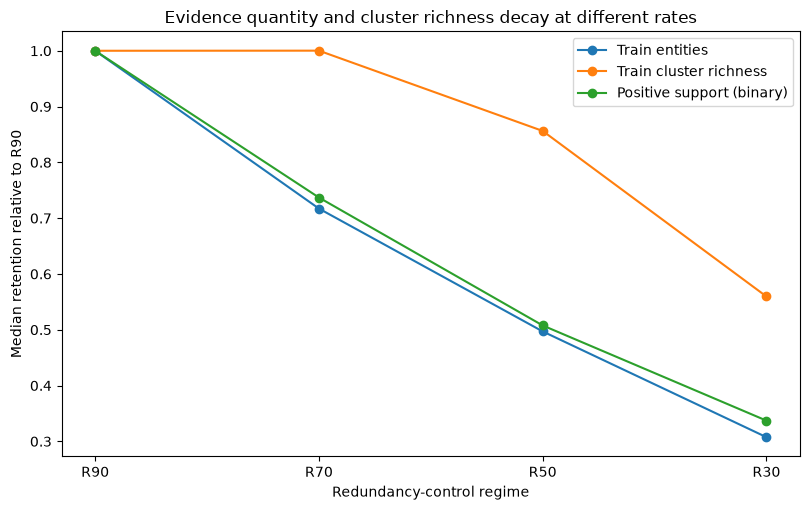

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq22_evidence_quantity_structure/figures/rq22_R_evidence_retention.png


In [17]:

# Figure 1 — R removes entities faster than cluster richness.
r_summary = (
    evidence.groupby("R", as_index=False)
    .agg(
        entity_retention=("entity_retention_to_R90", "median"),
        cluster_richness=("cluster_richness_to_R90", "median"),
        positive_support_retention=("positive_support_retention_to_R90", "median"),
    )
)
r_summary["order"] = r_summary["R"].map({90: 0, 70: 1, 50: 2, 30: 3})
r_summary = r_summary.sort_values("order")

fig, ax = plt.subplots(figsize=(8.2, 5.2))
ax.plot(r_summary["order"], r_summary["entity_retention"], marker="o", label="Train entities")
ax.plot(r_summary["order"], r_summary["cluster_richness"], marker="o", label="Train cluster richness")
ax.plot(r_summary["order"], r_summary["positive_support_retention"], marker="o", label="Positive support (binary)")
ax.set_xticks(r_summary["order"], [f"R{r}" for r in r_summary["R"]])
ax.set_xlabel("Redundancy-control regime")
ax.set_ylabel("Median retention relative to R90")
ax.set_title("Evidence quantity and cluster richness decay at different rates")
ax.legend()
fig.tight_layout()

path = FIG_DIR / "rq22_R_evidence_retention.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


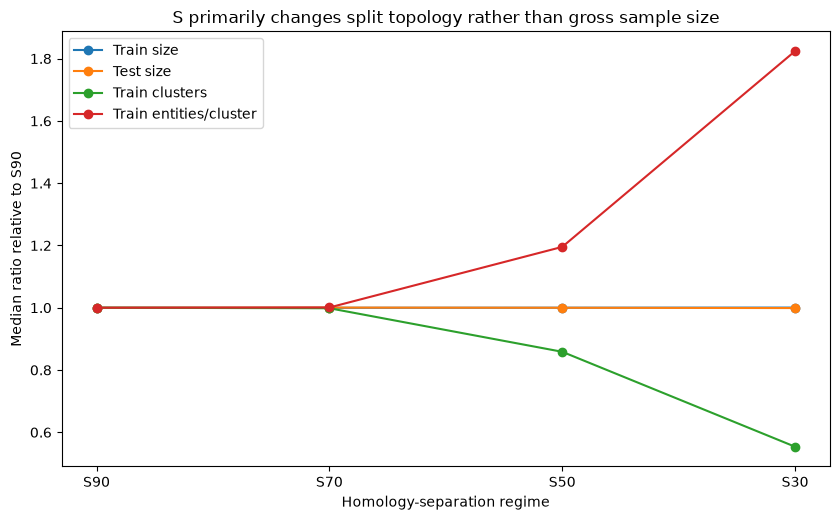

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq22_evidence_quantity_structure/figures/rq22_S_topology_vs_size.png


In [18]:

# Figure 2 — S changes cluster topology much more than gross train/test size.
s_summary = (
    evidence.groupby("S", as_index=False)
    .agg(
        train_size=("train_size_ratio_to_S90", "median"),
        test_size=("test_size_ratio_to_S90", "median"),
        train_clusters=("train_cluster_ratio_to_S90", "median"),
        test_clusters=("test_cluster_ratio_to_S90", "median"),
        train_density=("train_density_ratio_to_S90", "median"),
    )
)
s_summary["order"] = s_summary["S"].map({90: 0, 70: 1, 50: 2, 30: 3})
s_summary = s_summary.sort_values("order")

fig, ax = plt.subplots(figsize=(8.5, 5.3))
ax.plot(s_summary["order"], s_summary["train_size"], marker="o", label="Train size")
ax.plot(s_summary["order"], s_summary["test_size"], marker="o", label="Test size")
ax.plot(s_summary["order"], s_summary["train_clusters"], marker="o", label="Train clusters")
ax.plot(s_summary["order"], s_summary["train_density"], marker="o", label="Train entities/cluster")
ax.set_xticks(s_summary["order"], [f"S{s}" for s in s_summary["S"]])
ax.set_xlabel("Homology-separation regime")
ax.set_ylabel("Median ratio relative to S90")
ax.set_title("S primarily changes split topology rather than gross sample size")
ax.legend()
fig.tight_layout()

path = FIG_DIR / "rq22_S_topology_vs_size.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


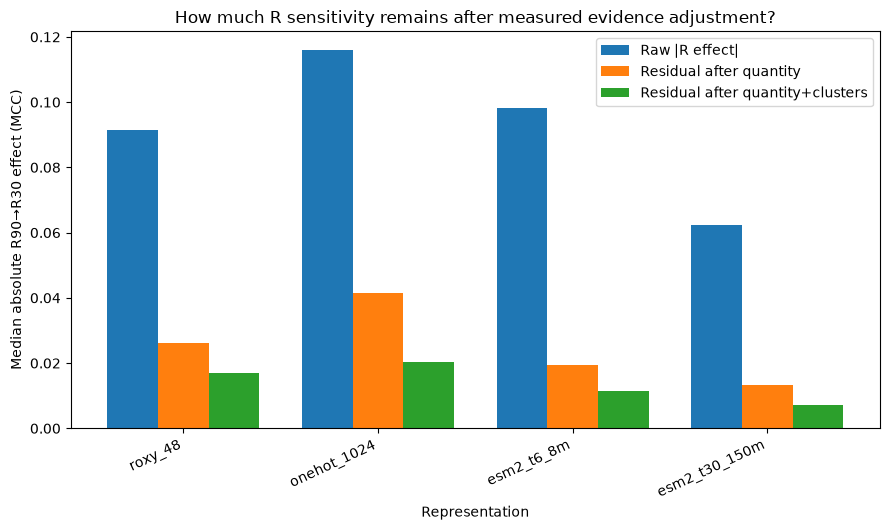

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq22_evidence_quantity_structure/figures/rq22_residual_R_by_representation.png


In [19]:

# Figure 3 — residual R effect after evidence adjustment, by representation.
plot_rep = residual_by_representation.copy()
plot_rep["representation"] = pd.Categorical(
    plot_rep["representation"], categories=REP_ORDER, ordered=True
)
plot_rep = plot_rep.sort_values("representation")

x = np.arange(len(plot_rep))
width = 0.26

fig, ax = plt.subplots(figsize=(9.0, 5.4))
ax.bar(x - width, plot_rep["median_raw_abs_R"], width=width, label="Raw |R effect|")
ax.bar(x, plot_rep["median_Q_residual_abs_R"], width=width, label="Residual after quantity")
ax.bar(x + width, plot_rep["median_QS_residual_abs_R"], width=width, label="Residual after quantity+clusters")
ax.set_xticks(x, plot_rep["representation"].astype(str), rotation=25, ha="right")
ax.set_ylabel("Median absolute R90→R30 effect (MCC)")
ax.set_xlabel("Representation")
ax.set_title("How much R sensitivity remains after measured evidence adjustment?")
ax.legend()
fig.tight_layout()

path = FIG_DIR / "rq22_residual_R_by_representation.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


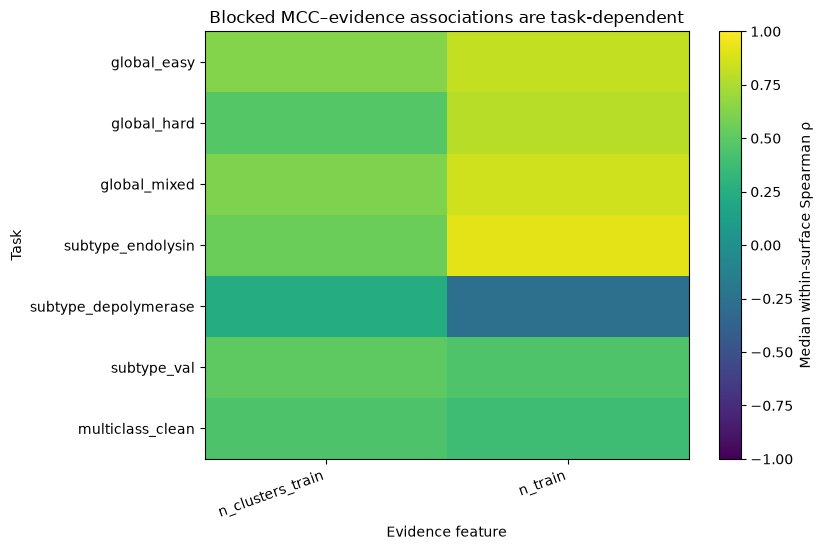

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq22_evidence_quantity_structure/figures/rq22_task_evidence_association_heatmap.png


In [20]:

# Figure 4 — task-specific blocked association with training quantity vs cluster richness.
features_plot = ["n_train", "n_clusters_train"]
tmp = assoc_by_task[assoc_by_task["feature"].isin(features_plot)].copy()

pivot = tmp.pivot(index="task", columns="feature", values="median_rho")
pivot = pivot.reindex(index=list(TASK_PATHS))

fig, ax = plt.subplots(figsize=(8.3, 5.6))
im = ax.imshow(pivot.to_numpy(dtype=float), aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(pivot.columns)), pivot.columns, rotation=20, ha="right")
ax.set_yticks(range(len(pivot.index)), pivot.index)
ax.set_xlabel("Evidence feature")
ax.set_ylabel("Task")
ax.set_title("Blocked MCC–evidence associations are task-dependent")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Median within-surface Spearman ρ")
fig.tight_layout()

path = FIG_DIR / "rq22_task_evidence_association_heatmap.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


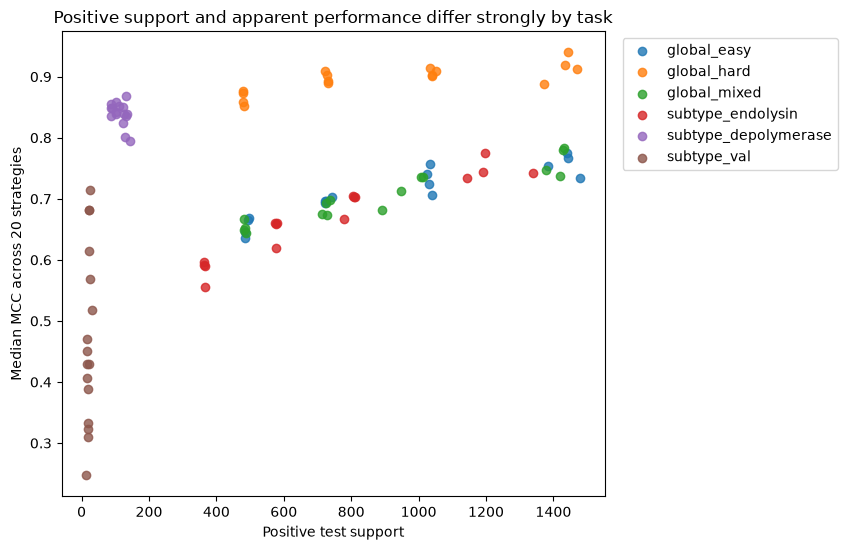

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq22_evidence_quantity_structure/figures/rq22_positive_support_vs_performance.png


In [21]:

# Figure 5 — positive test support versus median cell MCC for binary tasks.
fig, ax = plt.subplots(figsize=(8.6, 5.6))

for task in BINARY_TASKS:
    sub = binary_cells[binary_cells["task"].eq(task)]
    ax.scatter(
        sub["n_positive_test"],
        sub["median_mcc"],
        label=task,
        alpha=0.8,
    )

ax.set_xlabel("Positive test support")
ax.set_ylabel("Median MCC across 20 strategies")
ax.set_title("Positive support and apparent performance differ strongly by task")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()

path = FIG_DIR / "rq22_positive_support_vs_performance.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)



## 17. Scientific interpretation guardrails

RQ22 should answer:

1. How strongly does raw performance track `n_train` and `n_test`?
2. Is cluster richness more informative than entity count within blocked model surfaces?
3. Does S alter gross sample size or primarily cluster topology?
4. How strongly do positive support and prevalence track binary-task performance?
5. Is the Low-N regime distinguished by support scarcity and/or larger model-to-model variability?
6. How much of the raw R90→R30 effect remains after:
   - train-size adjustment;
   - train-size + cluster-richness adjustment?
7. Does this residual fraction differ by task, representation, or learner?
8. Does adding categorical R still increase descriptive fit after quantity + structure + S are already represented?
9. Are there rank/conditioning problems that make R non-separable from measured evidence quantities?

### Allowed conclusions

If residual R effects remain substantial:

> **The effect of redundancy control cannot be reduced to gross sample size or measured cluster richness alone.**

If most of the R effect disappears:

> **Much of the apparent redundancy penalty is statistically aligned with the amount and structure of evidence removed.**

If R becomes rank-deficient after evidence adjustment:

> **R is too tightly coupled to measured evidence state to identify a separate residual contribution with this factorial alone.**

That is an important methodological result and should not be disguised as a null effect.

### Explicit exclusions

RQ22 does not:

- claim causal mediation;
- treat separately reconstructed cluster IDs as nested identical clusters across R;
- infer common-test effects;
- redo VAL uncertainty;
- select deployment models.


## 18. Export canonical RQ22 artifacts

In [22]:

exports = {
    "rq22_evidence_cell_state.tsv": evidence,
    "rq22_performance_evidence_merged.tsv": merged,
    "rq22_unique_cell_performance_evidence.tsv": cell_state,
    "rq22_unique_cell_associations.tsv": unique_cell_associations,
    "rq22_surface_associations.tsv": surface_associations,
    "rq22_surface_association_summary.tsv": surface_assoc_summary,
    "rq22_associations_by_task.tsv": assoc_by_task,
    "rq22_associations_by_representation.tsv": assoc_by_representation,
    "rq22_associations_by_algorithm.tsv": assoc_by_algorithm,
    "rq22_R90_R30_contrasts.tsv": R_extreme,
    "rq22_S90_S30_contrasts.tsv": S_extreme,
    "rq22_R_unique_dataset_contrasts.tsv": R_unique,
    "rq22_S_unique_dataset_contrasts.tsv": S_unique,
    "rq22_contrast_associations.tsv": contrast_associations,
    "rq22_nested_unique_cell_models.tsv": nested_models,
    "rq22_binary_support_nested_models.tsv": binary_nested_models,
    "rq22_surface_residual_R.tsv": surface_residual_R,
    "rq22_residual_R_by_task.tsv": residual_by_task,
    "rq22_residual_R_by_representation.tsv": residual_by_representation,
    "rq22_residual_R_by_algorithm.tsv": residual_by_algorithm,
    "rq22_binary_support_summary.tsv": binary_support_summary,
    "rq22_support_vs_model_spread.tsv": support_vs_model_spread,
    "rq22_global_summary.tsv": global_summary,
}

for filename, df in exports.items():
    path = RQ22_OUT / filename
    df.to_csv(path, sep="\t", index=False)
    print(f"Wrote {filename}: {len(df)} rows")

manifest = {
    "rq": "RQ22",
    "question": "how much performance is explained by evidence quantity and structure?",
    "primary_metric": PRIMARY_METRIC,
    "n_supervised_model_rows": int(len(master)),
    "n_unique_dataset_cells": int(len(cell_state)),
    "n_model_surfaces": int(len(surface_residual_R)),
    "binary_tasks": BINARY_TASKS,
    "multiclass_tasks": MULTICLASS_TASKS,
    "global_model_unit": "unique task×R×S dataset cell with median MCC across 20 strategies",
    "blocked_model_unit": "task×representation×algorithm surface",
    "R_primary_treatment": "ordered categorical factor",
    "S_primary_treatment": "ordered categorical factor",
    "causal_claim": False,
    "training_performed": False,
    "prediction_regeneration_performed": False,
    "bootstrap_performed": False,
    "common_test_recalculation_performed": False,
}

with open(RQ22_OUT / "rq22_manifest.json", "w", encoding="utf-8") as fh:
    json.dump(manifest, fh, indent=2)

print("Wrote rq22_manifest.json")


Wrote rq22_evidence_cell_state.tsv: 112 rows
Wrote rq22_performance_evidence_merged.tsv: 2240 rows
Wrote rq22_unique_cell_performance_evidence.tsv: 112 rows
Wrote rq22_unique_cell_associations.tsv: 163 rows
Wrote rq22_surface_associations.tsv: 2560 rows
Wrote rq22_surface_association_summary.tsv: 19 rows
Wrote rq22_associations_by_task.tsv: 128 rows
Wrote rq22_associations_by_representation.tsv: 76 rows
Wrote rq22_associations_by_algorithm.tsv: 95 rows
Wrote rq22_R90_R30_contrasts.tsv: 560 rows
Wrote rq22_S90_S30_contrasts.tsv: 560 rows
Wrote rq22_R_unique_dataset_contrasts.tsv: 28 rows
Wrote rq22_S_unique_dataset_contrasts.tsv: 28 rows
Wrote rq22_contrast_associations.tsv: 24 rows
Wrote rq22_nested_unique_cell_models.tsv: 5 rows
Wrote rq22_binary_support_nested_models.tsv: 5 rows
Wrote rq22_surface_residual_R.tsv: 140 rows
Wrote rq22_residual_R_by_task.tsv: 7 rows
Wrote rq22_residual_R_by_representation.tsv: 4 rows
Wrote rq22_residual_R_by_algorithm.tsv: 5 rows
Wrote rq22_binary_suppo

## 19. Execution gates

In [23]:

required_exports = [
    *exports.keys(),
    "rq22_manifest.json",
]

assert len(master) == 2240
assert len(evidence) == 112
assert len(cell_state) == 112
assert len(merged) == 2240
assert len(surface_residual_R) == 140
assert len(R_extreme) == 560
assert len(S_extreme) == 560
assert len(R_unique) == 28
assert len(S_unique) == 28

assert evidence["shared_train_test_clusters"].eq(0).all()
assert evidence["n_train"].gt(0).all()
assert evidence["n_test"].gt(0).all()
assert evidence["n_clusters_train"].gt(0).all()
assert evidence["n_clusters_test"].gt(0).all()

assert surface_residual_R[
    [
        "raw_R_effect_abs_median",
        "Q_residual_R_effect_abs_median",
        "QS_residual_R_effect_abs_median",
    ]
].notna().all().all()

assert nested_models["r2"].notna().all()
assert binary_nested_models["r2"].notna().all()

assert all((RQ22_OUT / f).is_file() for f in required_exports)

figure_files = sorted(p.name for p in FIG_DIR.glob("*.png"))
assert len(figure_files) >= 5, f"Expected ≥5 figures, found {figure_files}"

print("RQ22_EXECUTION_GATES_OK")
print("Supervised model rows:", len(master))
print("Unique task×R×S evidence cells:", len(evidence))
print("Complete model surfaces:", len(surface_residual_R))
print("R90→R30 model contrasts:", len(R_extreme))
print("S90→S30 model contrasts:", len(S_extreme))
print("Unique R dataset contrasts:", len(R_unique))
print("Unique S dataset contrasts:", len(S_unique))
print("Exports:", len(required_exports))
print("Figures:", figure_files)
print()
print(
    "Interpretation status: execution gates passed. "
    "Assign REAL-DATA PASS only after the executed notebook and outputs are inspected."
)


RQ22_EXECUTION_GATES_OK
Supervised model rows: 2240
Unique task×R×S evidence cells: 112
Complete model surfaces: 140
R90→R30 model contrasts: 560
S90→S30 model contrasts: 560
Unique R dataset contrasts: 28
Unique S dataset contrasts: 28
Exports: 24
Figures: ['rq22_R_evidence_retention.png', 'rq22_S_topology_vs_size.png', 'rq22_positive_support_vs_performance.png', 'rq22_residual_R_by_representation.png', 'rq22_task_evidence_association_heatmap.png']

Interpretation status: execution gates passed. Assign REAL-DATA PASS only after the executed notebook and outputs are inspected.
